# Part 2 - Fine-Tuning Diffusion Models for Domain-Specific Image Generation

Stable Diffusion 1.5 fine-tuned with LoRA on **Naruto BLIP Captions**. Two runs with the same data, steps and
learning rate differ only in LoRA rank (4 vs 16). Both are compared with the base model on 20 fixed prompts
(`part2/eval/part2_prompts.json`, committed before training) for quality (KID), prompt alignment (CLIP),
diversity (LPIPS) and cost (GPU-hours, peak memory). Every number below is computed in this notebook.

In [1]:
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
    text=True).stdout.strip()
import glob
if not commit:  # on Kaggle there is no git checkout: the code dataset carries the commit it was built from
    found = glob.glob("/kaggle/input/**/member-nikhil/COMMIT", recursive=True)
    commit = open(found[0]).read().strip() if found else "unknown"
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': '7e66071', 'python': '3.12.10', 'torch': '2.11.0+cu128', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}


In [2]:
import os, json, importlib.metadata as md
# Run from the member folder so every path below is relative to part2/member-nikhil/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())
print({p: md.version(p) for p in ["diffusers", "transformers", "peft", "accelerate", "torchmetrics", "open_clip_torch", "lpips", "datasets"]})
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
pd.set_option("display.max_colwidth", 80)
GEN = "data/processed/part2/generated"
os.makedirs("eval", exist_ok=True)

cwd: C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\part2\member-nikhil
{'diffusers': '0.42.0', 'transformers': '5.22.2', 'peft': '0.21.2', 'accelerate': '1.15.0', 'torchmetrics': '1.9.0', 'open_clip_torch': '3.3.0', 'lpips': '0.1.4', 'datasets': '5.1.0'}


## 2.1 Data preparation
Corrupted images and perceptual-hash duplicates are removed, images are resized to 512x512, and the set is split 90/10 with seed 266. Test images are used only for KID.

In [3]:
from src.part2.data_prep import prepare_dataset
data_report = prepare_dataset("data/processed/part2")
json.dump(data_report, open("eval/part2_data_report.json", "w"), indent=2)
print(data_report["description"])
pd.Series({k: v for k, v in data_report.items() if k != "description"})

Repo card metadata block was not found. Setting CardData to empty.


Naruto BLIP Captions: 1221 images of Naruto anime character art, each
with a short BLIP-generated caption describing the scene. Limitations: (1) captions are
auto-generated by BLIP, so they are sometimes generic or miss specific character names;
(2) the dataset over-represents a small set of recurring characters and poses, so styles
and compositions less common in the source material are under-represented.


total_before_cleaning    1221
corrupted_removed           0
duplicates_removed          0
train_size               1098
test_size                 123
dtype: int64

## 2.2 Fine-tuning: two LoRA runs (rank 4 and rank 16), same data and step budget
The official diffusers `train_text_to_image_lora.py` script. Peak memory is the training process's own (`torch.cuda.max_memory_reserved`), so the 16 GB budget can be checked directly.

In [4]:
from src.part2.train_runs import run_training
run_reports = [run_training("run1_lora_r4"), run_training("run2_lora_r16")]
json.dump(run_reports, open("eval/part2_training.json", "w"), indent=2)
training = pd.DataFrame(run_reports).set_index("run_name")
training

,rank,trainable_params,learning_rate,max_train_steps,effective_batch_size,peak_gpu_memory_gb,training_time_seconds,gpu_hours,gpu,reused,trained_at
run_name,,,,,,,,,,,
run1_lora_r4,4,797184,0.0001,1200,4,4.12,1323.8,0.368,NVIDIA GeForce RTX 4090,True,2026-11-14 02:27
run2_lora_r16,16,3188736,0.0001,1200,4,4.15,1304.5,0.362,NVIDIA GeForce RTX 4090,True,2026-11-14 02:49


## 2.3 Image generation: base model and both runs, 20 fixed prompts x seeds 0 and 1
Same sampler for every model (30 steps, guidance 7.5). Stable Diffusion's safety checker runs on every image: a flagged image is published, shown and rated as a black image. Its unfiltered copy stays on this machine (`generated/raw/`) and is used only for the metrics, so a false positive cannot count as a black image in KID, CLIP or LPIPS.

In [5]:
from src.part2.generate import generate_all
records = generate_all("../eval/part2_prompts.json", GEN)
meta = pd.DataFrame(records)
print(len(records), "images;", meta.groupby("model").size().to_dict(), "| flagged by the safety checker:", int(meta["nsfw"].sum()))
meta[meta.nsfw].groupby(["model", "category"]).size().rename("flagged")

W1117 14:15:23.094000 58872 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


W1117 14:15:23.828000 58872 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (137 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


120 images; {'base': 40, 'run1_lora_r4': 40, 'run2_lora_r16': 40} | flagged by the safety checker: 11


model          category     
run1_lora_r4   in_domain        4
run2_lora_r16  compositional    1
               in_domain        6
Name: flagged, dtype: int64

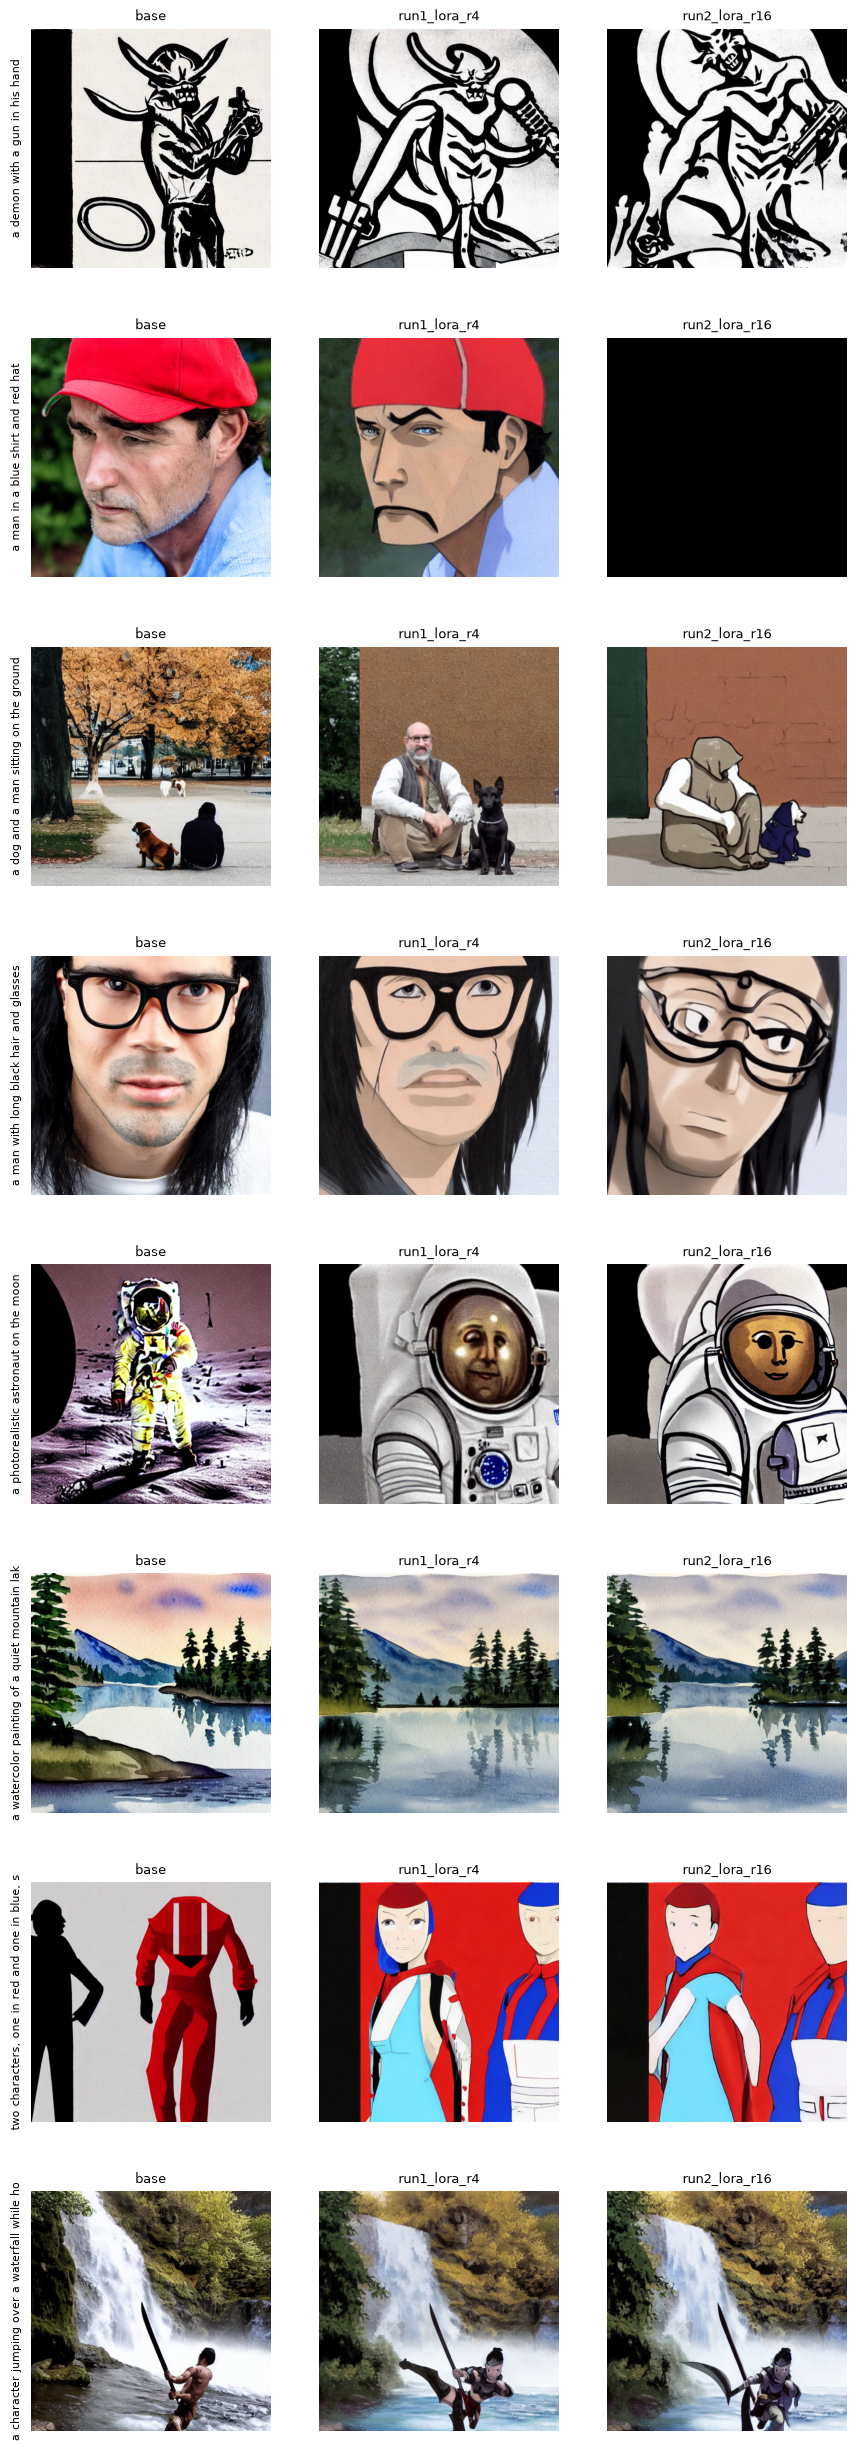

In [6]:
MODELS = ["base", "run1_lora_r4", "run2_lora_r16"]
by_cat = meta[meta.model == "base"].drop_duplicates("prompt").groupby("category")["prompt"].apply(list)
grid_prompts = by_cat["in_domain"][:4] + by_cat["out_of_domain"][:2] + by_cat["compositional"][:2]

def show(prompt, seed=0, models=MODELS, ax_row=None):
    for ax, m in zip(ax_row, models):
        r = meta[(meta.model == m) & (meta.prompt == prompt) & (meta.seed == seed)].iloc[0]
        ax.imshow(Image.open(os.path.join(GEN, m, r.file_name))); ax.axis("off")
        ax.set_title(m, fontsize=9)

fig, axes = plt.subplots(len(grid_prompts), 3, figsize=(9, 3.1 * len(grid_prompts)))
for row, prompt in zip(axes, grid_prompts):
    show(prompt, ax_row=row)
    row[0].text(-20, 256, prompt[:45], rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

## 2.4 Evaluation
KID compares the 20 in-domain generations of each model with the test images (noisy at this sample size). CLIP score is prompt-image cosine similarity over all 40 images; LPIPS is the distance between the two seeds of each prompt.

In [7]:
from src.part2.evaluate import evaluate_model
RAW = os.path.join(GEN, "raw")   # unfiltered copies: metrics measure the model, not the filter
evals = {m: evaluate_model(m, os.path.join(RAW, m), records, "data/processed/part2/test") for m in MODELS}
metrics = [{k: v for k, v in e.items() if not k.startswith("per_")} for e in evals.values()]
json.dump(metrics, open("eval/part2_metrics.json", "w"), indent=2)
# Final run: the lower KID of the two LoRA runs (KID is the primary domain-quality metric).
FINAL = min(["run1_lora_r4", "run2_lora_r16"], key=lambda m: evals[m]["kid_mean"])
print("final run:", FINAL)
pd.DataFrame(metrics).set_index("model")

C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\lpips\weights\v0.1\alex.pth


C:\Users\018322096\Downloads\GENAI-Lab2\data266-lab2-team42\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


final run: run2_lora_r16


,kid_mean,kid_std,clip_score_mean,lpips_diversity_mean
model,,,,
base,0.118309,0.012469,0.311785,0.686370
run1_lora_r4,0.050512,0.008437,0.305278,0.674279
run2_lora_r16,0.023302,0.005658,0.304028,0.660816


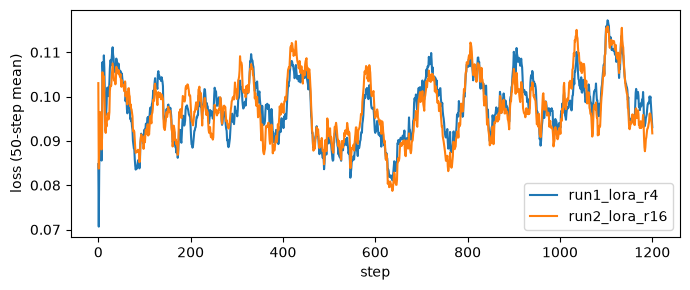

In [8]:
# The loss curve of each run, from its training log.
import re
fig, ax = plt.subplots(figsize=(7, 3))
for rep in run_reports:
    log = open(os.path.join("models/part2", rep["run_name"], "train.log"), encoding="utf-8", errors="replace").read()
    steps = {}
    for step, loss in re.findall(r"(\d+)/\d+ \[[^]]*step_loss=([\d.]+)", log):
        steps.setdefault(int(step), []).append(float(loss))
    xs = sorted(steps); ys = pd.Series([np.mean(steps[x]) for x in xs]).rolling(50, min_periods=1).mean()
    ax.plot(xs, ys, label=rep["run_name"])
ax.set_xlabel("step"); ax.set_ylabel("loss (50-step mean)"); ax.legend(); plt.tight_layout(); plt.show()

In [9]:
# One results table: baseline (base SD 1.5) vs both runs. Human win rate is filled from the raters' files (section below).
results = pd.DataFrame(metrics).set_index("model")[["kid_mean", "kid_std", "clip_score_mean", "lpips_diversity_mean"]]
results["gpu_hours"] = training["gpu_hours"]; results["peak_gpu_memory_gb"] = training["peak_gpu_memory_gb"]
results

,kid_mean,kid_std,clip_score_mean,lpips_diversity_mean,gpu_hours,peak_gpu_memory_gb
model,,,,,,
base,0.118309,0.012469,0.311785,0.686370,NaN,NaN
run1_lora_r4,0.050512,0.008437,0.305278,0.674279,0.368,4.12
run2_lora_r16,0.023302,0.005658,0.304028,0.660816,0.362,4.15


### Failure modes
Picked by the metrics, not by hand: the out-of-domain and compositional prompts where the final run's CLIP score falls furthest below the base model's, and the prompt whose two seeds are most alike (lowest LPIPS).

out_of_domain | a steampunk city skyline at sunset
compositional | three characters sitting around a campfire at night


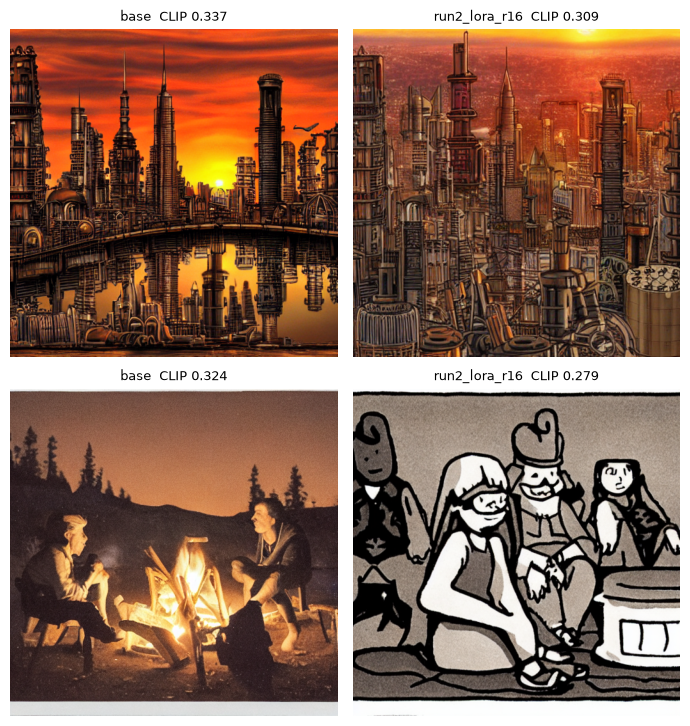

most repeated: 'a man with black hair and blue eyes pointing at the camera' LPIPS 0.561 (mean over prompts 0.661)


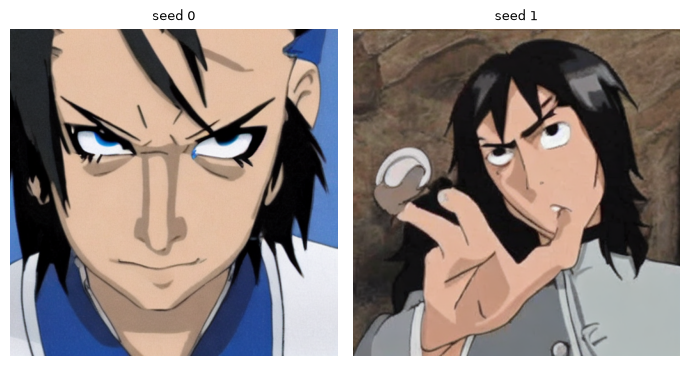

category
compositional    0.710017
in_domain        0.632374
out_of_domain    0.668498
Name: lpips, dtype: float64

In [10]:
base_clip = {(r["prompt"], r["seed"]): r["clip"] for r in evals["base"]["per_image"]}
final_imgs = pd.DataFrame(evals[FINAL]["per_image"])
final_imgs["clip_drop"] = [base_clip[(p, s)] - c for p, s, c in zip(final_imgs["prompt"], final_imgs["seed"], final_imgs["clip"])]
picks = [final_imgs[final_imgs.category == c].sort_values("clip_drop", ascending=False).iloc[0] for c in ["out_of_domain", "compositional"]]
fig, axes = plt.subplots(2, 2, figsize=(7, 7.4))
for row, r in zip(axes, picks):
    show(r.prompt, r.seed, ["base", FINAL], row)
    row[0].set_title("base  CLIP {:.3f}".format(base_clip[(r.prompt, r.seed)]), fontsize=9)
    row[1].set_title("{}  CLIP {:.3f}".format(FINAL, r["clip"]), fontsize=9)
    print(r.category, "|", r.prompt)
plt.tight_layout(); plt.show()

lp = pd.DataFrame(evals[FINAL]["per_prompt"]).sort_values("lpips")
same = lp.iloc[0]
print("most repeated: '{}' LPIPS {:.3f} (mean over prompts {:.3f})".format(same["prompt"], same["lpips"], lp["lpips"].mean()))
fig, axes = plt.subplots(1, 2, figsize=(7, 3.7))
for ax, seed in zip(axes, [0, 1]):
    r = meta[(meta.model == FINAL) & (meta.prompt == same["prompt"]) & (meta.seed == seed)].iloc[0]
    ax.imshow(Image.open(os.path.join(GEN, FINAL, r.file_name))); ax.axis("off"); ax.set_title("seed %d" % seed, fontsize=9)
plt.tight_layout(); plt.show()
lp.groupby("category")["lpips"].mean()

**What the failure cases show** (images above; numbers from the cells above):

1. **The trained style overrides the prompt on out-of-domain requests.** Both LoRA runs draw "a photorealistic astronaut on the moon" (grid above) as a flat anime illustration, ignoring "photorealistic". For "a steampunk city skyline at sunset" the final run keeps the city but loses most of the sunset (CLIP 0.309 vs 0.337 for the base model).
2. **Compositional prompts lose attributes.** For "three characters sitting around a campfire at night" the final run draws a grey daytime sketch with no fire (CLIP 0.279 vs 0.324). In "two characters, one in red and one in blue" both characters wear red *and* blue: colours are not bound to the right character.
3. **Less variety inside the training domain.** The two seeds of an in-domain prompt are more alike (mean LPIPS 0.632) than for compositional prompts (0.710), and the final run's overall seed diversity is lower than the base model's (0.661 vs 0.686). No prompt gave two near-identical images (the closest pair scored LPIPS 0.561).
4. **Safety-checker false positives.** 10 of the 11 flagged images are in-domain "a man ..." prompts from the two LoRA runs; the base model had none. The checker reacts to the anime style, so these images are published black.

**Which run is final, and why: `run2_lora_r16` (rank 16).** On the same data, steps and learning rate, its KID against the real test images is less than half of rank 4's (0.023 vs 0.051, base 0.118). Its CLIP score is essentially the same (0.304 vs 0.305), and it took the same compute (0.36 vs 0.37 GPU-hours, 4.2 GB peak). The cost is a small loss of seed diversity (LPIPS 0.661 vs 0.674). KID uses only 20 generated images per model, so it is noisy; still, the gap (0.027) is about five times its standard deviation (0.006).

### Safety
**License:** Naruto BLIP Captions (`lambdalabs/naruto-blip-captions`) contains copyrighted characters, so the dataset and both adapters are for non-commercial research and education only. **NSFW filter:** every image above was generated with Stable Diffusion's safety checker on (count of flagged images printed in 2.3). **Memorization:** for 10 in-domain generations of the final run, the most similar training image by CLIP similarity; the 3 closest pairs are shown.

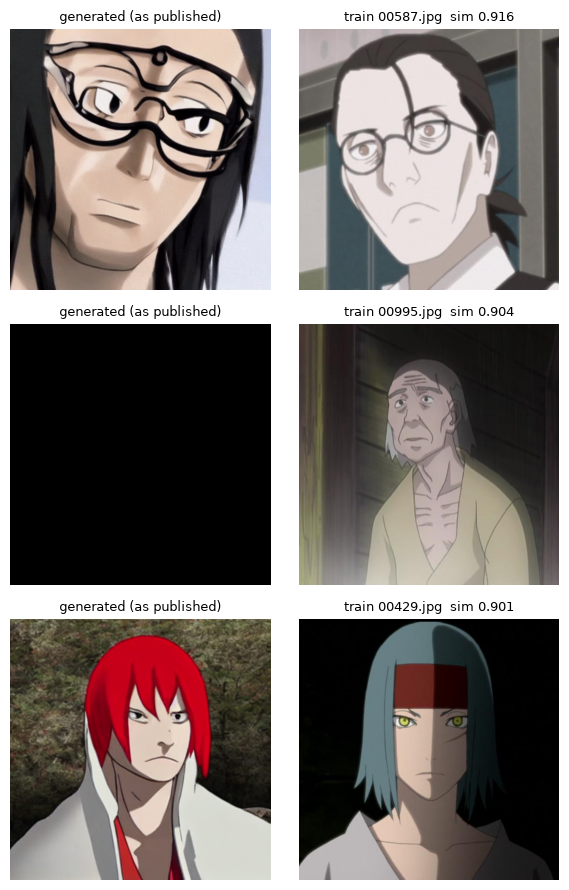

,generated,closest_train,similarity
0,a_man_with_long_black_hair_and_glasses_seed0.png,00587.jpg,0.916063
1,a_man_with_long_black_hair_and_glasses_seed1.png,00995.jpg,0.904311
2,a_man_with_red_hair_and_a_white_cloak_seed1.png,00429.jpg,0.901031


In [11]:
from src.part2.evaluate import memorization_check
in_domain = [r["file_name"] for r in records if r["model"] == FINAL and r["category"] == "in_domain"]
closest = memorization_check(os.path.join(RAW, FINAL), "data/processed/part2/train", in_domain)
memorization = {"model": FINAL, "closest_pairs": closest}
json.dump(memorization, open("eval/part2_memorization.json", "w"), indent=2)
fig, axes = plt.subplots(3, 2, figsize=(6, 9))
for row, p in zip(axes, closest):
    row[0].imshow(Image.open(os.path.join(GEN, FINAL, p["generated"]))); row[0].set_title("generated (as published)", fontsize=9)
    row[1].imshow(Image.open(os.path.join("data/processed/part2/train", p["closest_train"]))); row[1].set_title("train {}  sim {:.3f}".format(p["closest_train"], p["similarity"]), fontsize=9)
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.show()
pd.DataFrame(closest)

### Human evaluation (blinded)
25 pairs of the final run vs the base model (same prompt and seed, both passed by the safety checker), left/right randomized with seed 266. Raters (both members and one outside rater) use the generated HTML page, which shows no model or file names, and pick L or R for domain style and for prompt match. Their files go in `eval/part2_human_eval/ratings/`.

In [12]:
import glob
from src.part2.human_eval import build_blind_pairs, prepare_rater_sheet, compute_win_rates
build_blind_pairs(GEN, "base", FINAL, os.path.join(GEN, "generation_metadata.json"), "eval/part2_human_eval")
print(prepare_rater_sheet("eval/part2_human_eval/blind_pairs.json", "data/processed/part2/part2_rater_sheet.html"))
ratings = sorted(glob.glob("eval/part2_human_eval/ratings/*.json"))
if ratings:
    win = compute_win_rates(ratings, "eval/part2_human_eval/answer_key.json", FINAL)
    print(json.dumps(win, indent=2))
else:
    print("no ratings yet: rerun this cell after the three raters return their files")

data/processed/part2/part2_rater_sheet.html
{
  "raters": [
    "Anushka",
    "Ayush",
    "Nikhil"
  ],
  "style": {
    "win_rate_all_votes": 0.37333333333333335,
    "votes": 75,
    "win_rate_by_rater": {
      "Anushka": 0.28,
      "Ayush": 0.6,
      "Nikhil": 0.24
    },
    "majority_win_rate": 0.2,
    "pairs_with_all_raters": 25,
    "unanimous_share": 0.32,
    "fleiss_kappa": 0.031155015197568203
  },
  "prompt": {
    "win_rate_all_votes": 0.41333333333333333,
    "votes": 75,
    "win_rate_by_rater": {
      "Anushka": 0.32,
      "Ayush": 0.56,
      "Nikhil": 0.36
    },
    "majority_win_rate": 0.4,
    "pairs_with_all_raters": 25,
    "unanimous_share": 0.56,
    "fleiss_kappa": 0.39516129032258057
  }
}


## Push to Hugging Face
Both adapters (weights, run report and a model card written from the numbers above) and all 120 images with their metadata.

In [13]:
from huggingface_hub import get_token
from src.part2.push_to_hf import model_card, push_lora, push_image_dataset
if get_token():
    for rep in run_reports:
        print(push_lora(RUN_DIR := os.path.join("models/part2", rep["run_name"]),
                        model_card(rep, metrics, data_report, memorization, FINAL)))
    print(push_image_dataset(GEN))
else:
    print("not logged in to Hugging Face (hf auth login): nothing pushed")

not logged in to Hugging Face (hf auth login): nothing pushed
